# 01 · Análise exploratória

**Pergunta do negócio:** qual a chance de o empregador deixar de existir antes do fim de um
consignado de *t* meses?

Este notebook responde às perguntas que definem o problema antes de qualquer modelo. Cada seção
termina com a **decisão** que o achado gerou.

1. Quanto tempo de acompanhamento temos?
2. O que conta como "a empresa deixou de existir"?
3. Quando os eventos acontecem?
4. Quem é o público-alvo?
5. Uma foto única dos dados vaza o desfecho?
6. Como é a curva de sobrevivência?
7. Quais sinais separam quem sobrevive de quem não sobrevive?

**Para reproduzir:** `uv run python -m consig_risk.data` e `uv run python -m consig_risk.features.build`,
depois `make notebooks`. As consultas rodam com DuckDB direto sobre os Parquets; o notebook inteiro
leva poucos minutos.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lifelines import KaplanMeierFitter

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
con = duckdb.connect()

R = "data/interim/receita"
con.sql(
    f"CREATE VIEW est23 AS SELECT * FROM read_parquet('{R}/2023-05/Estabelecimentos/*.parquet') WHERE matriz"
)
con.sql(
    f"CREATE VIEW est26 AS SELECT * FROM read_parquet('{R}/2026-10/Estabelecimentos/*.parquet') WHERE matriz"
)
con.sql(f"CREATE VIEW emp23 AS SELECT * FROM read_parquet('{R}/2023-05/Empresas/*.parquet')")
con.sql(f"CREATE VIEW emp26 AS SELECT * FROM read_parquet('{R}/2026-10/Empresas/*.parquet')")
con.sql(f"CREATE VIEW sim23 AS SELECT * FROM read_parquet('{R}/2023-05/Simples/*.parquet')")
con.sql(f"CREATE VIEW sim26 AS SELECT * FROM read_parquet('{R}/2026-10/Simples/*.parquet')")
con.sql(f"CREATE VIEW motivos AS SELECT * FROM read_parquet('{R}/2026-10/Motivos/*.parquet')")
con.sql(f"CREATE VIEW naturezas AS SELECT * FROM read_parquet('{R}/2026-10/Naturezas/*.parquet')")
con.sql("CREATE VIEW cohort AS SELECT * FROM 'data/processed/cohort.parquet'")


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


# Paleta de referência (validada para daltonismo); no máximo 3 séries categóricas por gráfico.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "text.color": INK,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "lines.linewidth": 2,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "figure.dpi": 110,
    }
)

## 1. Quanto tempo de acompanhamento temos?

In [2]:
datas = q("""
  SELECT '2023-05' AS foto, max(data_situacao_cadastral) AS data_referencia FROM est23
  UNION ALL
  SELECT '2026-10', max(data_situacao_cadastral) FROM est26
""")
display(datas)
origem, desfecho = datas["data_referencia"]
print(f"acompanhamento: {(desfecho - origem).days / 30.4375:.1f} meses")

,foto,data_referencia
0,2023-05,2023-05-13
1,2026-10,2026-10-11


acompanhamento: 41.0 meses


A foto mais antiga disponível é de 13/05/2023 e a mais recente de 11/10/2026: **41 meses** de
acompanhamento. A data de referência de cada foto é o evento cadastral mais recente registrado
nela.

**Decisão:** horizontes de até 36 meses são *validados* com desfecho observado. Acima disso, o
risco é extrapolado pelo modelo, e o relatório do agent precisa dizer isso.

## 2. O que conta como "a empresa deixou de existir"?

In [3]:
SITUACAO = {1: "nula", 2: "ativa", 3: "suspensa", 4: "inapta", 8: "baixada"}
trans = q("""
  SELECT a.situacao_cadastral AS s0, b.situacao_cadastral AS s1, count(*) AS n
  FROM est23 a JOIN est26 b USING (cnpj_basico) GROUP BY ALL
""")
trans["s0"] = trans["s0"].map(SITUACAO)
trans["s1"] = trans["s1"].map(SITUACAO)
tabela = trans.pivot_table(index="s0", columns="s1", values="n", aggfunc="sum", fill_value=0) / 1e3
print("matrizes por situação em 2023-05 (linhas) e em 2026-10 (colunas), em milhares")
display(tabela.round(0))

matrizes por situação em 2023-05 (linhas) e em 2026-10 (colunas), em milhares


s1,ativa,baixada,inapta,nula,suspensa
s0,,,,,
ativa,"14,455.0","4,425.0","3,346.0",4.0,60.0
baixada,4.0,"23,569.0",1.0,2.0,0.0
inapta,608.0,842.0,"6,040.0",4.0,4.0
nula,0.0,0.0,0.0,88.0,0.0
suspensa,5.0,18.0,17.0,0.0,178.0


In [4]:
motivos = q("""
  SELECT CASE b.situacao_cadastral WHEN 4 THEN 'ativa → inapta' ELSE 'ativa → baixada' END AS transicao,
         m.descricao AS motivo, count(*) AS n
  FROM est23 a JOIN est26 b USING (cnpj_basico)
  LEFT JOIN motivos m ON m.codigo = b.motivo_situacao_cadastral
  WHERE a.situacao_cadastral = 2 AND b.situacao_cadastral IN (4, 8)
  GROUP BY 1, 2 QUALIFY row_number() OVER (PARTITION BY transicao ORDER BY n DESC) <= 4
  ORDER BY transicao, n DESC
""")
motivos["% da transição"] = 100 * motivos["n"] / motivos.groupby("transicao")["n"].transform("sum")
display(motivos)

reativ = q("""
  SELECT count(*) FILTER (WHERE b.situacao_cadastral = 2) AS voltaram, count(*) AS inaptas
  FROM est23 a JOIN est26 b USING (cnpj_basico) WHERE a.situacao_cadastral = 4
""")
print(
    f"inaptas em 2023 que voltaram a ser ativas até 2026: {100 * reativ.voltaram[0] / reativ.inaptas[0]:.1f}%"
)

,transicao,motivo,n,% da transição
0,ativa → baixada,EXTINCAO POR ENCERRAMENTO LIQUIDACAO VOLUNTARIA,4307287,97.5
1,ativa → baixada,OBITO DO MEI - TITULAR FALECIDO,82248,1.9
2,ativa → baixada,BAIXA DE PRODUTOR RURAL,20733,0.5
3,ativa → baixada,INCORPORACAO,9604,0.2
4,ativa → inapta,OMISSAO DE DECLARACOES,3344571,100.0
5,ativa → inapta,INEXISTENCIA DE FATO,1005,0.0
6,ativa → inapta,SOLICITACAO DA ADMINISTRACAO TRIBUTARIA ESTADU...,275,0.0
7,ativa → inapta,PRATICA IRREGULAR DE OPERACAO DE COMERCIO EXTE...,214,0.0


inaptas em 2023 que voltaram a ser ativas até 2026: 8.1%


- **Inapta é, na prática, "omissão de declarações"** (motivo 63): a empresa parou de prestar contas
  ao fisco, ou seja, foi abandonada sem baixa formal. Só cerca de 8% das inaptas voltam a ser
  ativas em 41 meses.
- **Baixada é quase toda "extinção por encerramento voluntário".** Incorporação, quando os
  funcionários passam para outra empresa, é rara.
- Suspensa e nula são residuais.

**Decisão:** o evento é **sair da situação ativa por qualquer motivo** (baixada, inapta, suspensa
ou nula). Para o credor, uma empresa que deixou de declarar ao fisco é tão arriscada quanto uma
baixada: ela não opera mais uma folha de pagamento normal. Como análise de sensibilidade, a
modelagem também mede o resultado com o evento "só baixada".

## 3. Quando os eventos acontecem?

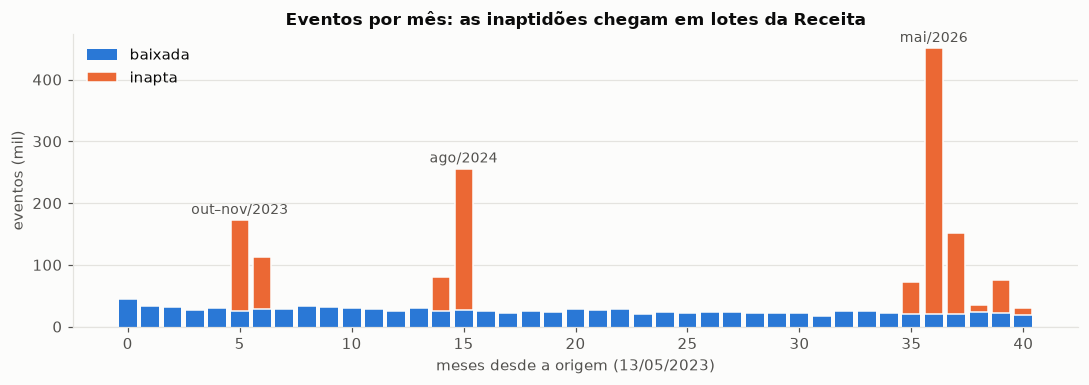

In [5]:
mensal = q("""
  SELECT floor(duracao_meses)::INT AS mes,
         count(*) FILTER (WHERE tipo_evento = 'baixada') AS baixada,
         count(*) FILTER (WHERE tipo_evento = 'inapta') AS inapta
  FROM cohort WHERE evento GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(10, 3.6))
x = mensal["mes"].to_numpy()
ax.bar(x, mensal["baixada"] / 1e3, width=0.8, color=BLUE, label="baixada")
ax.bar(
    x,
    mensal["inapta"] / 1e3,
    width=0.8,
    bottom=mensal["baixada"] / 1e3,
    color=ORANGE,
    label="inapta",
    edgecolor=SURFACE,
    linewidth=1,
)
for mes, rotulo in [(5, "out–nov/2023"), (15, "ago/2024"), (36, "mai/2026")]:
    total = (mensal.loc[mensal.mes == mes, ["baixada", "inapta"]].sum(axis=1).iloc[0]) / 1e3
    ax.annotate(
        rotulo,
        (mes, total),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=INK2,
    )
ax.set_xlabel("meses desde a origem (13/05/2023)")
ax.set_ylabel("eventos (mil)")
ax.set_title("Eventos por mês: as inaptidões chegam em lotes da Receita")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

As baixas são contínuas (cerca de 25 mil por mês, em leve queda). As inaptidões chegam em **lotes
anuais** de processamento da Receita: out–nov/2023, jul–ago/2024 e abr–jun/2026, sem lote em
2025, o que explica o lote de 2026 maior.

Consequências:

- A data de uma inaptidão é **administrativa**: marca quando a Receita constatou a omissão, não
  quando a empresa parou. Muitas dessas empresas já estavam paradas na origem, e o modelo pode
  reconhecer isso pelos sinais disponíveis (sem ECF, dívida ativa, exclusão do Simples).
- O formato da curva *dentro* de um ano depende do calendário dos lotes, não da empresa.

**Decisão:** o risco é reportado e **avaliado em horizontes anuais (12, 24 e 36 meses)**, que é
também a granularidade natural dos prazos de consignado. Prazos intermediários são interpolados
na curva do modelo.

## 4. Quem é o público-alvo?

In [6]:
publico = q("""
  SELECT CASE WHEN coalesce(s.opcao_mei, false) THEN 'MEI'
              ELSE 'grupo ' || left(e.natureza_juridica, 1) END AS grupo,
         count(*) AS empresas_ativas,
         100 * avg((b.situacao_cadastral <> 2)::INT) AS pct_saiu_41m
  FROM est23 a JOIN est26 b USING (cnpj_basico)
  JOIN emp23 e USING (cnpj_basico) LEFT JOIN sim23 s USING (cnpj_basico)
  WHERE a.situacao_cadastral = 2 GROUP BY 1 ORDER BY 2 DESC
""")
publico["descricao"] = publico["grupo"].map(
    {
        "MEI": "Microempreendedor individual",
        "grupo 2": "Entidades empresariais",
        "grupo 3": "Entidades sem fins lucrativos",
        "grupo 4": "Pessoas físicas com CNPJ",
        "grupo 1": "Administração pública",
        "grupo 5": "Organismos internacionais",
    }
)
display(publico)

display(
    q("""
  SELECT e.natureza_juridica, n.descricao, count(*) AS empresas_ativas,
         100 * avg((b.situacao_cadastral <> 2)::INT) AS pct_saiu_41m
  FROM est23 a JOIN est26 b USING (cnpj_basico)
  JOIN emp23 e USING (cnpj_basico) LEFT JOIN sim23 s USING (cnpj_basico)
  LEFT JOIN naturezas n ON n.codigo = e.natureza_juridica
  WHERE a.situacao_cadastral = 2 AND NOT coalesce(s.opcao_mei, false)
    AND left(e.natureza_juridica, 1) = '4'
  GROUP BY ALL ORDER BY 3 DESC LIMIT 4
""")
)

,grupo,empresas_ativas,pct_saiu_41m,descricao
0,MEI,12211507,45.0,Microempreendedor individual
1,grupo 2,8458933,25.9,Entidades empresariais
2,grupo 3,1073275,12.1,Entidades sem fins lucrativos
3,grupo 4,489686,4.9,Pessoas físicas com CNPJ
4,grupo 1,55608,1.4,Administração pública
5,grupo 5,574,1.4,Organismos internacionais
6,grupo 0,6,0.0,NaN


,natureza_juridica,descricao,empresas_ativas,pct_saiu_41m
0,4120,Produtor Rural (Pessoa Física),482975,4.3
1,4014,Empresa Individual Imobiliária,5972,38.8
2,4090,Candidato a Cargo Político Eletivo,739,99.3


- **MEI** são 12,2 milhões das 22,3 milhões de empresas ativas e saem quase duas vezes mais
  (45%). MEI pode ter no máximo um empregado, então é praticamente irrelevante para consignado,
  e mantê-lo faria o modelo aprender a dinâmica errada.
- O **grupo 4** é de pessoas físicas com CNPJ: produtor rural pessoa física, empresa individual
  imobiliária e **candidatos a cargo político**, um CNPJ temporário de campanha (99% encerrados
  em 41 meses).
- O **grupo 1** (administração pública) tem consignado próprio, e o 5 (organismos
  internacionais) é irrelevante.

**Decisão:** o público-alvo são empresas **ativas na origem, não MEI, dos grupos de natureza 2
(empresariais) e 3 (sem fins lucrativos)**. O grupo 3 entra porque condomínios, associações e
entidades religiosas contratam CLT. São **9,5 milhões de empresas**.

## 5. Uma foto única dos dados vaza o desfecho?

O jeito mais barato de montar o dataset seria usar só a foto mais recente: a idade e a situação
atual dão a duração e o evento, e as demais colunas viram features. O problema é que essas
colunas são medidas **depois** do desfecho. Comparando as duas fotos, dá para medir se elas
mudam junto com o fechamento.

In [7]:
vaz = q("""
  SELECT b.situacao_cadastral <> 2 AS saiu,
         100 * avg((e0.porte IS DISTINCT FROM e1.porte)::INT) AS pct_mudou_porte,
         100 * avg((e0.capital_social IS DISTINCT FROM e1.capital_social)::INT) AS pct_mudou_capital,
         100 * avg((coalesce(s0.opcao_simples, false) AND NOT coalesce(s1.opcao_simples, false))::INT)
           AS pct_saiu_do_simples
  FROM est23 a JOIN est26 b USING (cnpj_basico)
  JOIN emp23 e0 USING (cnpj_basico) JOIN emp26 e1 USING (cnpj_basico)
  LEFT JOIN sim23 s0 USING (cnpj_basico) LEFT JOIN sim26 s1 USING (cnpj_basico)
  WHERE a.situacao_cadastral = 2 AND NOT coalesce(s0.opcao_mei, false)
    AND left(e0.natureza_juridica, 1) IN ('2', '3')
  GROUP BY 1 ORDER BY 1
""")
vaz["saiu"] = vaz["saiu"].map({False: "continuou ativa", True: "saiu"})
display(vaz)

,saiu,pct_mudou_porte,pct_mudou_capital,pct_saiu_do_simples
0,continuou ativa,3.2,7.6,9.2
1,saiu,0.9,2.2,43.7


In [8]:
# A ECF do ano N vence em julho de N+1. Na origem (13/05/2023), a de 2022 ainda não existia.
ecf = q("""
  WITH reg AS (
    SELECT cnpj_basico, ano FROM 'data/interim/regimes/regimes.parquet' WHERE ano IN (2021, 2022)
  )
  SELECT ano_usado,
         100 * avg(evento::INT) FILTER (WHERE NOT tem_ecf AND NOT opcao_simples) AS pct_saiu_sem_ecf_fora_simples
  FROM (
    SELECT c.evento, c.opcao_simples, y.ano_usado,
           EXISTS (SELECT 1 FROM reg WHERE reg.cnpj_basico = c.cnpj_basico AND reg.ano = y.ano_usado) AS tem_ecf
    FROM cohort c CROSS JOIN (VALUES (2021), (2022)) y(ano_usado)
    WHERE c.amostra < 100
  ) GROUP BY 1 ORDER BY 1
""")
display(ecf)

,ano_usado,pct_saiu_sem_ecf_fora_simples
0,2021,35.8
1,2022,37.7


- **Porte e capital não vazam:** quase não mudam entre as fotos, e mudam até menos nas empresas
  que fecharam. A hipótese inicial de que o porte "não informado" denunciaria as baixadas estava
  errada.
- **O Simples vaza muito:** cerca de 44% das empresas que fecharam saíram do Simples entre as
  fotos, contra 9% das que sobreviveram. Numa foto única, "não está no Simples" seria uma
  *consequência* do fechamento aprendida como *causa*.
- **A ECF tem uma armadilha de calendário:** usar o ano de 2022, que só é entregue em julho de
  2023, eleva a taxa de saída do grupo "sem ECF" de forma pequena mas real.

**Decisão:** o dataset de treino usa **duas fotos**: features na origem (2023-05) e desfecho na
foto de 2026-10. O ano de ECF é calculado pela regra de entrega
(`ecf_year_available` em `features/company.py`), e testes automatizados garantem que nada
posterior à data de referência entra nas features.

## 6. Como é a curva de sobrevivência?

Todas as empresas têm o mesmo acompanhamento (a foto de desfecho é a mesma para todas), então a
proporção de eventos em 41 meses já é um estimador sem viés. A curva de Kaplan-Meier mostra o
caminho até lá. Usamos a amostra de 10% por hash do CNPJ (cerca de 950 mil empresas), que é a
mesma estratégia do treino.

amostra: 953,904 empresas, 24.4% com evento


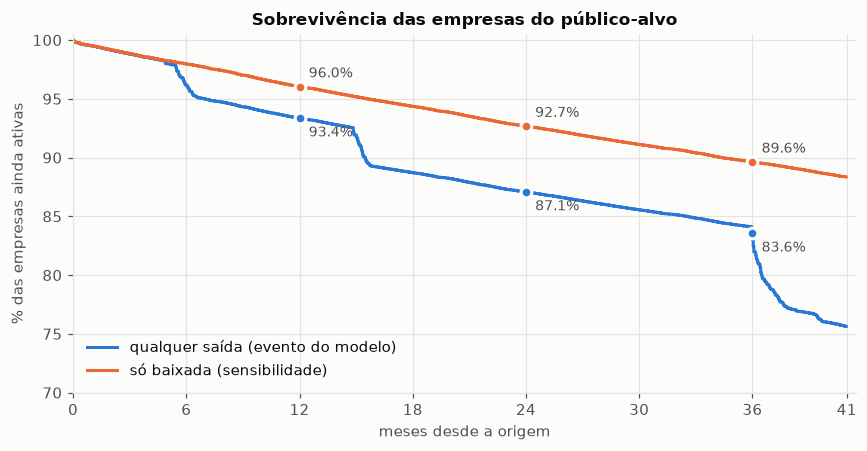

In [9]:
amostra = q("""
  SELECT duracao_meses, evento, tipo_evento, idade_meses
  FROM cohort WHERE amostra < 100
""")
print(f"amostra: {len(amostra):,} empresas, {100 * amostra.evento.mean():.1f}% com evento")

fig, ax = plt.subplots(figsize=(8, 4.2))
horizontes = [12, 24, 36]
for rotulo, evento, cor in [
    ("qualquer saída (evento do modelo)", amostra["evento"], BLUE),
    ("só baixada (sensibilidade)", amostra["tipo_evento"].eq("baixada"), ORANGE),
]:
    km = KaplanMeierFitter().fit(amostra["duracao_meses"], evento)
    sf = km.survival_function_.iloc[:, 0]
    ax.step(sf.index, 100 * sf.values, where="post", color=cor, label=rotulo)
    for h in horizontes:
        v = 100 * km.predict(h)
        ax.plot(h, v, "o", color=cor, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(
            f"{v:.1f}%",
            (h, v),
            xytext=(6, -12 if cor == BLUE else 6),
            textcoords="offset points",
            fontsize=9,
            color=INK2,
        )
ax.set_xlim(0, 41.5)
ax.set_ylim(70, 100.5)
ax.set_xticks([0, 6, 12, 18, 24, 30, 36, 41])
ax.set_xlabel("meses desde a origem")
ax.set_ylabel("% das empresas ainda ativas")
ax.set_title("Sobrevivência das empresas do público-alvo")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

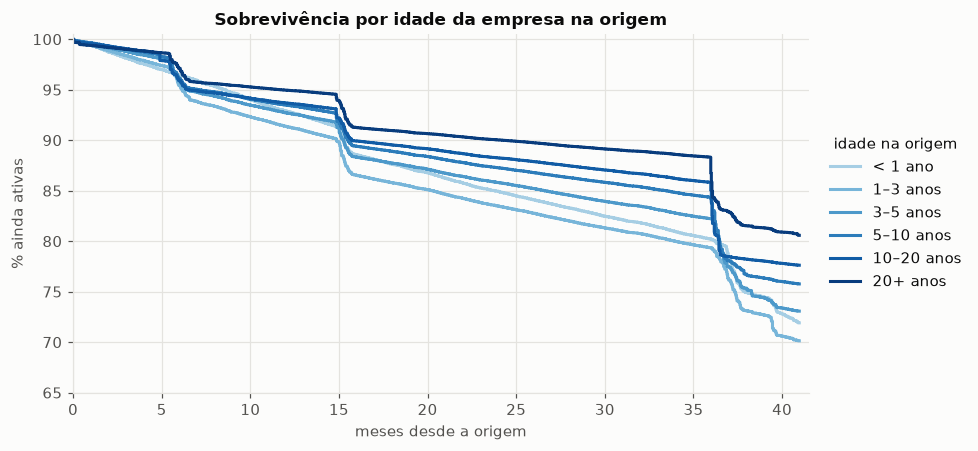

,idade na origem,empresas,% saiu em 12m,% saiu em 36m
0,< 1 ano,80243,7.1,19.8
1,1–3 anos,159601,8.6,20.7
2,3–5 anos,107573,7.3,17.8
3,5–10 anos,184174,6.5,15.8
4,10–20 anos,222867,6.3,14.9
5,20+ anos,199446,5.0,13.3


In [10]:
faixas = [
    (0, 12, "< 1 ano"),
    (12, 36, "1–3 anos"),
    (36, 60, "3–5 anos"),
    (60, 120, "5–10 anos"),
    (120, 240, "10–20 anos"),
    (240, 10_000, "20+ anos"),
]
tons = plt.cm.Blues(np.linspace(0.35, 0.95, len(faixas)))
fig, ax = plt.subplots(figsize=(9, 4.2))
linhas = []
for (lo, hi, rotulo), cor in zip(faixas, tons):
    g = amostra[(amostra.idade_meses >= lo) & (amostra.idade_meses < hi)]
    km = KaplanMeierFitter().fit(g["duracao_meses"], g["evento"])
    sf = km.survival_function_.iloc[:, 0]
    ax.step(sf.index, 100 * sf.values, where="post", color=cor, label=rotulo)
    linhas.append((rotulo, len(g), 100 * (1 - km.predict(12)), 100 * (1 - km.predict(36))))
ax.set_xlim(0, 41.5)
ax.set_ylim(65, 100.5)
ax.set_xlabel("meses desde a origem")
ax.set_ylabel("% ainda ativas")
ax.set_title("Sobrevivência por idade da empresa na origem")
ax.legend(title="idade na origem", frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()
display(
    pd.DataFrame(linhas, columns=["idade na origem", "empresas", "% saiu em 12m", "% saiu em 36m"])
)

- Cerca de **1 em cada 4** empresas do público-alvo sai em 41 meses, e quase todo o risco vem da
  inaptidão: com o evento "só baixada", a perda cai para cerca de 1 em cada 9.
- **Empresas mais velhas sobrevivem mais**: em 36 meses, saem cerca de 21% das empresas de 1 a 3
  anos e 13% das com mais de 20 anos.
- **As curvas se cruzam.** Empresas com menos de 1 ano começam como as *menos* arriscadas e
  terminam entre as *mais* arriscadas. A omissão de declarações leva de 2 a 3 anos para virar
  inaptidão, então o risco da empresa nova aparece tarde. O efeito da idade muda com o
  horizonte.

**Decisão:** a idade entra como feature contínua, e o modelo precisa permitir efeitos que mudam
com o horizonte, o que um Cox de riscos proporcionais puro não faz. Isso favorece um modelo de
risco em tempo discreto por ano, que pode interagir as features com o período. A comparação
entre as alternativas fica para a modelagem.

## 7. Quais sinais separam quem sobrevive?

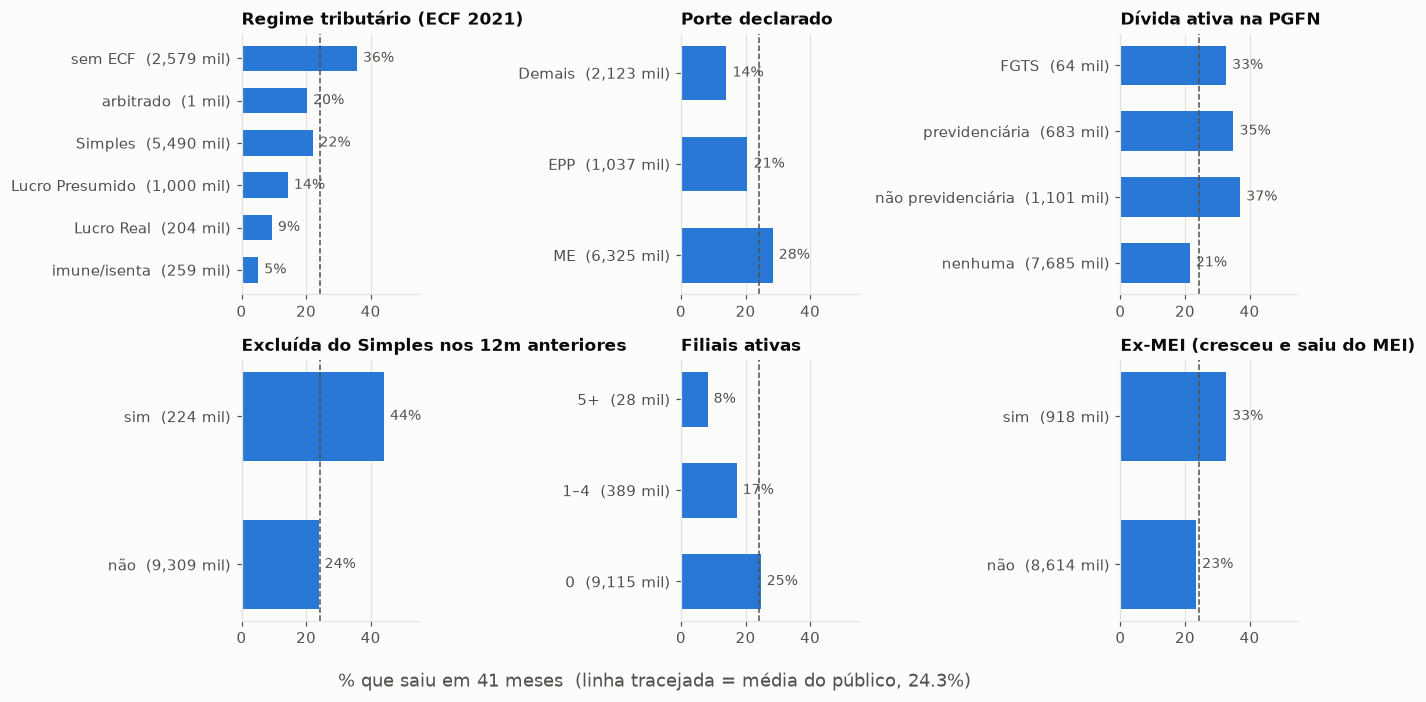

In [11]:
base = 100 * con.sql("SELECT avg(evento::INT) FROM cohort").fetchone()[0]


def taxa(col: str, ordem: list[str] | None = None, rotulos: dict | None = None) -> pd.DataFrame:
    df = q(f"""
      SELECT CAST({col} AS VARCHAR) AS nivel, count(*) AS empresas, 100 * avg(evento::INT) AS pct
      FROM cohort GROUP BY 1
    """)
    if rotulos:
        df["nivel"] = df["nivel"].map(lambda v: rotulos.get(v, v))
    if ordem:
        df["nivel"] = pd.Categorical(df["nivel"], ordem, ordered=True)
        df = df.sort_values("nivel")
    else:
        df = df.sort_values("pct")
    return df.dropna(subset=["nivel"])


SIM_NAO = {"false": "não", "true": "sim"}
paineis = {
    "Regime tributário (ECF 2021)": taxa(
        "regime_tributario",
        ["imune/isenta", "Lucro Real", "Lucro Presumido", "Simples", "arbitrado", "sem ECF"],
        {
            "imune_isenta": "imune/isenta",
            "real": "Lucro Real",
            "presumido": "Lucro Presumido",
            "simples": "Simples",
            "sem_ecf": "sem ECF",
        },
    ),
    "Porte declarado": taxa(
        "porte", ["ME", "EPP", "Demais"], {"01": "ME", "03": "EPP", "05": "Demais"}
    ),
    "Dívida ativa na PGFN": taxa(
        "CASE WHEN divida_fgts THEN 'FGTS' WHEN divida_previdenciaria THEN 'previdenciária' "
        "WHEN divida_nao_previdenciaria THEN 'não previdenciária' ELSE 'nenhuma' END",
        ["nenhuma", "não previdenciária", "previdenciária", "FGTS"],
    ),
    "Excluída do Simples nos 12m anteriores": taxa("excluido_simples_12m", ["não", "sim"], SIM_NAO),
    "Filiais ativas": taxa(
        "CASE WHEN n_filiais_ativas = 0 THEN '0' WHEN n_filiais_ativas < 5 THEN '1–4' ELSE '5+' END",
        ["0", "1–4", "5+"],
    ),
    "Ex-MEI (cresceu e saiu do MEI)": taxa("ex_mei", ["não", "sim"], SIM_NAO),
}

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (titulo, df) in zip(axes.flat, paineis.items()):
    y = np.arange(len(df))
    ax.barh(y, df["pct"], color=BLUE, height=0.6)
    ax.axvline(base, color=INK2, linestyle="--", linewidth=1)
    ax.set_yticks(y, [f"{n}  ({e / 1e3:,.0f} mil)" for n, e in zip(df["nivel"], df["empresas"])])
    for yi, v in zip(y, df["pct"]):
        ax.annotate(
            f"{v:.0f}%",
            (v, yi),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
            color=INK2,
        )
    ax.set_xlim(0, max(55, df["pct"].max() + 8))
    ax.set_title(titulo, loc="left")
    ax.grid(axis="y", visible=False)
fig.supxlabel(
    f"% que saiu em 41 meses  (linha tracejada = média do público, {base:.1f}%)", color=INK2
)
plt.tight_layout()
plt.show()

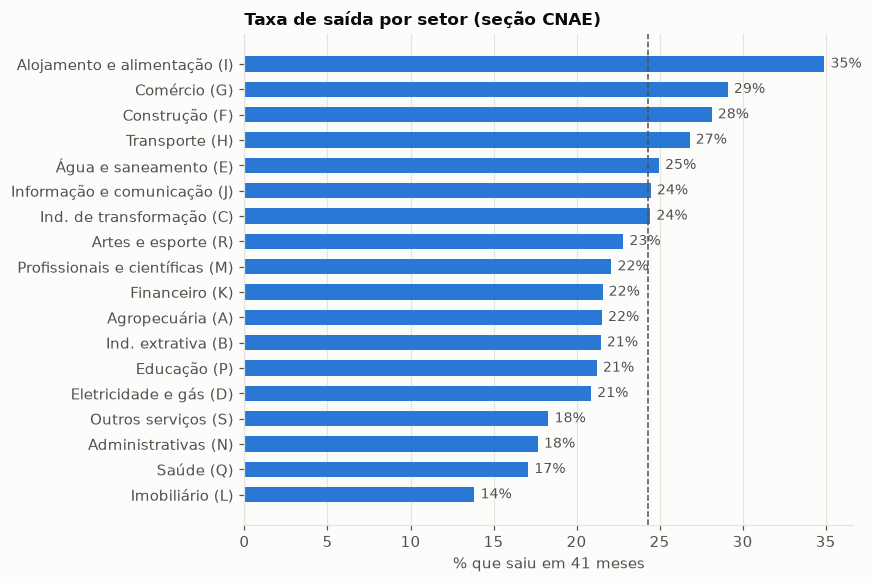

In [12]:
setor = q("""
  SELECT cnae_secao, count(*) AS empresas, 100 * avg(evento::INT) AS pct
  FROM cohort WHERE cnae_secao IS NOT NULL GROUP BY 1 HAVING count(*) > 5000 ORDER BY pct
""")
NOMES = {
    "A": "Agropecuária",
    "B": "Ind. extrativa",
    "C": "Ind. de transformação",
    "D": "Eletricidade e gás",
    "E": "Água e saneamento",
    "F": "Construção",
    "G": "Comércio",
    "H": "Transporte",
    "I": "Alojamento e alimentação",
    "J": "Informação e comunicação",
    "K": "Financeiro",
    "L": "Imobiliário",
    "M": "Profissionais e científicas",
    "N": "Administrativas",
    "O": "Adm. pública",
    "P": "Educação",
    "Q": "Saúde",
    "R": "Artes e esporte",
    "S": "Outros serviços",
    "T": "Serviços domésticos",
    "U": "Org. internacionais",
}
fig, ax = plt.subplots(figsize=(8, 5.4))
y = np.arange(len(setor))
ax.barh(y, setor["pct"], color=BLUE, height=0.6)
ax.axvline(base, color=INK2, linestyle="--", linewidth=1)
ax.set_yticks(y, [f"{NOMES.get(s, s)} ({s})" for s in setor["cnae_secao"]])
for yi, v in zip(y, setor["pct"]):
    ax.annotate(
        f"{v:.0f}%",
        (v, yi),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=INK2,
    )
ax.set_xlabel("% que saiu em 41 meses")
ax.set_title("Taxa de saída por setor (seção CNAE)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- **Regime tributário é o sinal mais forte.** Empresas fora do Simples que não entregaram ECF
  saem em cerca de 36%, contra 9% no Lucro Real e 5% nas imunes ou isentas. Não entregar a ECF
  é o próprio começo da omissão de declarações que leva à inaptidão.
- **Qualquer dívida ativa na PGFN** eleva a saída de 21% para 33–37%. Ao contrário do que eu
  esperava, **dívida de FGTS não é um sinal mais forte que as outras** (33%, contra 37% da não
  previdenciária), e é rara: só 64 mil empresas do público. Fica como achado, não como premissa.
- **Sair do Simples nos 12 meses anteriores** quase dobra a saída (44% contra 24%). A exclusão
  costuma vir de dívida ou de irregularidade, e aqui ela é medida *antes* da origem, então é um
  sinal legítimo, ao contrário do vazamento da seção 5.
- **Ex-MEI** (empresas que cresceram e saíram do MEI) arriscam mais (33% contra 23%): são
  pequenas e jovens.
- **Porte e filiais** seguem o esperado: empresas maiores e com mais estabelecimentos sobrevivem
  mais, que é exatamente o perfil de empregador relevante para consignado.
- **Setor:** alojamento e alimentação (35%), comércio, construção e transporte arriscam mais;
  imobiliário (14%), saúde e serviços administrativos arriscam menos. O efeito existe, mas é
  menor que o dos sinais fiscais.

**Decisão:** todos esses sinais entram como features candidatas. A importância de cada um será
medida no modelo, não decidida aqui, e o relatório do agent deve explicar **quais fatores mais
pesaram** para cada CNPJ.

## Resumo das decisões

| # | Achado | Decisão |
|---|---|---|
| 1 | 41 meses de acompanhamento entre as fotos | Validar até 36 meses; acima disso, extrapolar e avisar |
| 2 | Inapta é "omissão de declarações" e raramente volta | Evento = sair da situação ativa por qualquer motivo; "só baixada" como sensibilidade |
| 3 | Inaptidões chegam em lotes anuais da Receita | Avaliar e reportar o risco em horizontes anuais (12/24/36 meses) |
| 4 | MEI e naturezas 1, 4 e 5 não são empregadores do consignado privado | Público = ativas, não MEI, naturezas 2 e 3 (9,5 milhões) |
| 5 | O Simples vaza o desfecho numa foto única; a ECF tem armadilha de calendário | Duas fotos (origem 2023-05, desfecho 2026-10) e ano de ECF pela regra de entrega |
| 6 | As curvas por idade se cruzam: o efeito muda com o horizonte | Preferir modelos que permitam efeitos não proporcionais |
| 7 | Sinais fiscais (ECF, PGFN, Simples) dominam; setor e porte ajudam | Todos entram como candidatos; a importância sai do modelo |

**Limitações identificadas aqui:**

- Duas fotos não mostram o que acontece entre elas: uma empresa que ficou inapta em 2024 e foi
  reativada em 2026 aparece como sobrevivente.
- Não há número de funcionários nos dados abertos. "Empregador" é aproximado pela natureza
  jurídica e pela exclusão do MEI; porte, filiais e regime tributário funcionam como indicadores
  de tamanho.
- O risco do vínculo do funcionário (demissão) não é modelado; ver ADR-0002.